In [11]:
# Importing important libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
# Load a real dataset
df = pd.read_csv("heart.csv")
print(f"Successfully loaded dataset with shape: {df.shape}")

Successfully loaded dataset with shape: (1025, 14)


In [ ]:
# Automatically identify the target label column
# Depending on which Kaggle version you downloaded, the target is named 'target' or 'HeartDisease'
if 'target' in df.columns:
    target_col = 'target'
elif 'HeartDisease' in df.columns:
    target_col = 'HeartDisease'
else:
    raise KeyError("Could not find the target column. Please check your CSV file headers.")

In [ ]:
# Separate features and target label
X = df.drop(columns=[target_col])
y = df[target_col]

In [ ]:
# Split dataset into training set (80%) and testing set (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

In [ ]:
# Feature Scaling
# GaussianNB behaves much better and avoids numerical instability when variables are scaled
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# Initialize and Train the Gaussian Naive Bayes Model
nb_classifier = GaussianNB()
nb_classifier.fit(X_train_scaled, y_train)

GaussianNB()

In [ ]:
# Make Predictions
y_pred = nb_classifier.predict(X_test_scaled)

In [10]:
accuracy = accuracy_score(y_test, y_pred)
print("\n======================= MODEL EVALUATION =======================")
print(f"Accuracy Score: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))


======================= MODEL EVALUATION =======================
Accuracy Score: 82.93%

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.78      0.82       100
           1       0.81      0.88      0.84       105

    accuracy                           0.83       205
   macro avg       0.83      0.83      0.83       205
weighted avg       0.83      0.83      0.83       205

Confusion Matrix:
[[78 22]
 [13 92]]


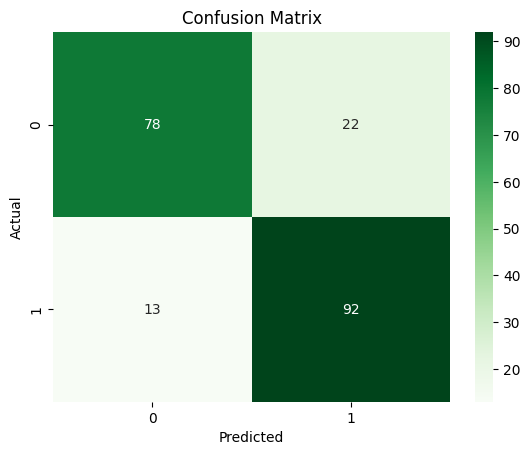

In [12]:
# Visualization of Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')

plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()